In [1]:
import starfile
from pathlib import Path
import seaborn as sns
import numpy as np
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt
import pandas as pd
import mrcfile
from matplotlib import gridspec
import ttctf

In [2]:
tomograms = pd.DataFrame([
    #{"name": "20231026_HippAu_26", "Label": "15F1"},
    {"name": "20240111_WaffleHipp_116", "Label": "15F1"},
    #{"name": "20240111_WaffleHipp_198", "Label": "15F1"},
    #{"name": "20241030_AMmilled12-1_15", "Label": "15F1", "active_zone": {"pre":[1], "post":[0]}},
    #{"name": "20231017_HippAu_132", "Label": "15F1"},
    #{"name": "20231017_EGmilled24-2_68", "Label": "15F1"},
    #{"name": "20241030_AMmilled12-2_30", "Label": "15F1"},
    #{"name": "20241030_AMmilled12-2_34", "Label": "15F1"},
    #{"name": "20240111_WaffleHipp_183", "Label": "15F1"},
    #{"name": "20240624_HippWaffle_36", "Label": "15F1"},
    #{"name": "20241030_AMmilled12-2_61", "Label": "15F1"},
    #{"name": "20231017_EGmilled24-2_60", "Label": "15F1"},
    #{"name": "20240920_HippWaffle_129", "Label": "5F11"},
    #{"name": "20240920_HippWaffle_136", "Label": "5F11"},
    #{"name": "20240920_HippWaffle_148", "Label": "5F11"},
    #{"name": "20240621_AMmilled10-1_115", "Label": "5F11"},
    #{"name": "20240621_AMmilled10-1_74", "Label": "5F11"},
    #{"name": "20240822_HippWaffle_31", "Label": "5F11"},
    #{"name": "20240920_HippWaffle_113", "Label": "5F11"},
    #{"name": "20241018_HippWaffleDual_117", "Label": "15F1and5F11"},
    #{"name": "20241018_HippWaffleDual_127", "Label": "15F1and5F11"},
    #{"name": "20241018_HippWaffleDual_166", "Label": "15F1and5F11"},
    #{"name": "20241018_HippWaffleDual_182", "Label": "15F1and5F11"},
    #{"name": "20240820_HippWaffle_97", "Label": "15F1and5F11"},
    #{"name": "20240819_HippWaffle_135", "Label": "15F1and5F11"},
    #{"name": "20241018_HippWaffleDual_177", "Label": "15F1and5F11"},
])

20240111_WaffleHipp_116


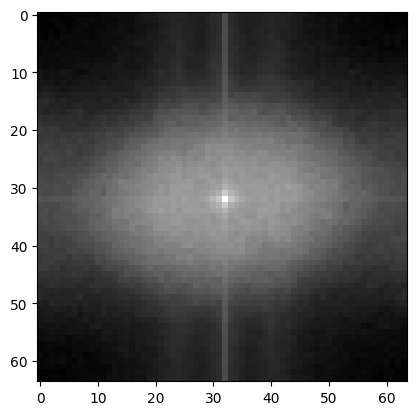

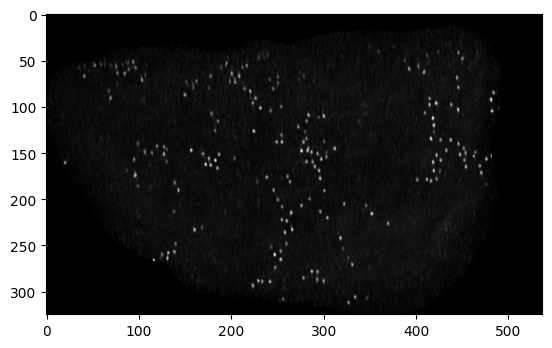

In [ ]:
from findingampa.utils.analysis import render_active_zonograms
import pymeshlab
from IPython.display import display
import matplotlib
import einops
%matplotlib inline
import torch
from ttctf.patch_grid import patch_grid
from ttctf.rotational_average import rotational_average_dft_2d
aunp_dfs = {}
for tomo in tomograms.itertuples():
    name = tomo.name
    label = tomo.Label
    print(name)
    basefolder = Path(f"/goliath/processing/Gouaux/CJS/BestTomo/ProcessingCJS/tomograms/{label}_tomograms/TOP_TOMOS/{name}/best_alignment")
    aunp_star = basefolder / "aunps" / "aunp_tm_BP.star"

    data = starfile.read(aunp_star)

    
    azs = (basefolder / "active_zonograms").glob("active_zonogram_*.mrc")
    for az in azs:
        patch_sidelength = 64
        with mrcfile.open(az, permissive=True) as mrc:
            res_ddw = torch.tensor(mrc.data.copy())

        project = -1 * torch.min(res_ddw, dim=0).values

        
        image = project.float()
        if image.ndim == 2:
            image = einops.rearrange(image, 'h w -> 1 h w')
        t, h, w = image.shape

        # normalise based on stats from central 50% in each dim
        h_low, h_high = int(0.25 * h), int(0.75 * h)
        w_low, w_high = int(0.25 * w), int(0.75 * w)
        image_center = image[:, h_low:h_high, w_low:w_high]
        image_mean = einops.reduce(image_center, 't h w -> 1 1 1', reduction='mean')
        image_std = torch.std(image_center, dim=(-1, -2), keepdim=True)
        image = (image - image_mean) / image_std

        # calculate power spectra from overlapping patches
        patches, patch_centers = patch_grid(
            images=image,
            patch_shape=(1, patch_sidelength, patch_sidelength),
            patch_step=(1, patch_sidelength // 2, patch_sidelength // 2)
        )
        patch_ps = torch.abs(torch.fft.fftn(patches, dim=(-2, -1))) ** 2
        mean_ps = einops.reduce(patch_ps, '... ph pw -> ph pw', reduction='mean')

        h, w = patch_sidelength, patch_sidelength
        rotationally_averaged_power_spectrum, _ = rotational_average_dft_2d(
            mean_ps,
            image_shape=(h, w),
            rfft=True,
            fftshifted=False,
        )
        mean_ps = torch.fft.fftshift(mean_ps)
        mean_ps = torch.log1p(mean_ps)
        plt.imshow(mean_ps.cpu().numpy(), cmap="gray")
        plt.show()
        plt.imshow(image[0],cmap="gray")
        plt.show()
